# 🧄 Garliclo ReAct Agent with Configurable Personas
**EECE 503P/798S: Agentic Systems — C4: Agent Personas & Thinking Mechanisms**

This notebook turns the C3 Garliclo business chatbot into a **ReAct agent** built with **LangGraph**. The
Thought → Action → Observation loop is written by hand as graph nodes and conditional edges; no prebuilt executor
(no `AgentExecutor`, no `create_react_agent`) is used. Three personas, each defined by **prompt traits and a matching
LLM configuration**, are compared across prompt-engineering variants and configuration sweeps.

| Grading item | Points | Where |
|---|---|---|
| Use-case summary and write-up | 10 | §1 |
| ReAct logic manually implemented | 30 | §3 tools, §7 prompt, §8 LangGraph loop, §9 demo |
| Persona design (prompt and configuration) | 20 | §5 |
| Configuration experimentation and comparison | 15 | §10–§12 |
| Clear instructions design | 10 | §4 |
| Creativity, clarity, and reflection quality | 15 | §13 reflection, Gradio app |

## 0. Setup
Keys are read from `.env` (`OPENAI_API_KEY`, and `GEMINI_API_KEY` for the top-k experiment). `.env` is never committed.

In [1]:
import truststore

truststore.inject_into_ssl()  # use the operating system's certificate store for HTTPS calls

import ast
import math
import datetime
import json
import os
import re
import time
from pathlib import Path
from typing import TypedDict

import httpx
from dotenv import load_dotenv
from langgraph.graph import END, START, StateGraph
from openai import OpenAI
from pypdf import PdfReader

load_dotenv(override=True)

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ME_DIR, LOG_DIR = BASE_DIR / "me", BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)

openai_client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"), max_retries=2, timeout=60)
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
MAX_LLM_CALLS = 6  # guardrail: at most 6 reasoning steps per question

print("✅ OpenAI key loaded" if os.getenv("OPENAI_API_KEY") else "⚠️ OPENAI_API_KEY missing")

✅ OpenAI key loaded


## 1. Use case
**Garliclo | Nader Garlic** is a real Lebanese supplier of air-peeled garlic, founded in 1980 by Joseph Nader
(main factory in Sin El Fil, delivery all over Lebanon). The scenario is reused from C3, as the assignment allows.

| | |
|---|---|
| **Agent goal** | Help food businesses buy peeled garlic: answer product questions, give exact quotes with delivery, plan quantities and storage, capture sales leads, and log complaints or questions the team must answer. |
| **Target audience** | Restaurant owners and chefs (shawarma and grill shops), industrial kitchens, butcheries, supermarkets and caterers in Lebanon, writing in English, Arabic or French. Households are not served. |
| **Tools** | `search_business_info` (profile lookup), `get_delivery_fee` (zone table), `calculate_quote` (exact totals), `record_customer_interest` (save a lead), `record_feedback` (log feedback or unanswered questions). |
| **Constraints** | Only facts from the business files; all arithmetic done by a tool, never by the model; no invented discounts, refunds or delivery dates; leads saved only with a real email; business customers only; at most 6 reasoning steps per question; replies under 120 words. |
| **Limitations** | No live stock, order or payment system: the agent cannot confirm availability, place or cancel orders, or take payment, so it hands those to the team (via the logging tools). Delivery fees, pack sizes and shelf life partly come from assumptions in the business file. Search is keyword-based (BM25), so unusual wording can miss a passage. |

The three personas split the work by **task**: a *Friendly Advisor* for first contact and sales, a *Strict Expert*
for exact quotes and kitchen planning, and a *Cautious Helper* for after-sales support.

## 2. Business knowledge
The C3 business files (`me/business_summary.txt`, `me/about_business.pdf`) are loaded and split into passages for the
search tool. Products and delivery zones are parsed into tables so the quote tool can compute exact totals.

In [2]:
business_summary = (ME_DIR / "business_summary.txt").read_text(encoding="utf-8")
profile_text = "\n".join(page.extract_text() or "" for page in PdfReader(ME_DIR / "about_business.pdf").pages)

PRODUCTS = {
    i + 1: {"name": en.strip(), "arabic": ar.strip(), "price": float(price)}
    for i, (en, ar, price) in enumerate(re.findall(
        r"^\d+\.[ \t]*(.+?)[ \t]+—[ \t]+(.+?)[ \t]+—[ \t]+\$(\d+\.\d{2}) per kg", business_summary, re.M))
}
ZONES = [
    {"zone": int(n), "name": name.strip(), "areas": [a.strip() for a in areas.split(",")], "fee": int(fee)}
    for n, name, areas, fee in re.findall(r"^Zone (\d) — (.+?): (.+?) — \$(\d+)[ \t]*$", business_summary, re.M)
]
FREE_DELIVERY_KG, FREE_DELIVERY_MAX_ZONE = 50, 3

# passages for the search tool: summary paragraphs + PDF sections
PASSAGES = [p.strip() for p in business_summary.split("\n\n") if p.strip()]
PASSAGES += [s.strip() for s in re.split(r"\n(?=\d{1,2}\. [A-Z])", profile_text) if len(s.strip()) > 40]

print(f"{len(PRODUCTS)} products, {len(ZONES)} delivery zones, {len(PASSAGES)} searchable passages")
for pid, p in PRODUCTS.items():
    print(f"  product {pid}: {p['name']} — ${p['price']:.2f}/kg")

4 products, 5 delivery zones, 29 searchable passages
  product 1: Peeled & trimmed, large cloves — $4.00/kg
  product 2: Peeled, untrimmed — $3.35/kg
  product 3: Peeled, untrimmed, imported from China — $3.20/kg
  product 4: Peeled, trimmed, frozen, imported from China — $3.00/kg


## 3. Tools
Each tool is a plain Python function that returns a short text **observation**. The `TOOLS` registry holds the
description and parameter list that are embedded in the system prompt, and that the action parser uses to map
arguments. Arithmetic lives in `calculate_quote`, so the model never computes totals itself.

In [3]:
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
STOPWORDS = set("the a an and or of to in for is are do does you your we our what how much many can i it on at by with "
                "from this that be as about any who which where when have has please".split())


def _stem(word: str) -> str:
    """Light stemmer so 'days'/'day' and 'founded'/'founder' match."""
    for suffix in ("ing", "ed", "er", "es", "s"):
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[:-len(suffix)]
    return word


def _words(text: str) -> list[str]:
    return [_stem(t) for t in re.findall(r"[a-z0-9\u0600-\u06ff]+", text.lower())]


def _tokens(text: str) -> set[str]:
    return {t for t in _words(text) if t not in STOPWORDS}


def _append_log(filename: str, entry: dict) -> None:
    with open(LOG_DIR / filename, "a", encoding="utf-8") as f:
        f.write(json.dumps({"time": datetime.datetime.now().isoformat(timespec="seconds"), **entry},
                           ensure_ascii=False) + "\n")


def find_zone(area: str) -> dict | None:
    a = area.strip().lower()
    for z in ZONES:
        names = [x.lower() for x in z["areas"]] + [z["name"].lower()]
        if any(a == n or a in n or n in a for n in names if len(n) > 2):
            return z
    return None


PASSAGE_TOKENS = [_words(p) for p in PASSAGES]
AVG_LEN = sum(map(len, PASSAGE_TOKENS)) / len(PASSAGE_TOKENS)


def bm25(query_terms: set[str], doc: list[str], k1: float = 1.5, b: float = 0.75) -> float:
    """BM25 relevance: rare words (e.g. 'storage') count more than common ones (e.g. 'garlic')."""
    n = len(PASSAGE_TOKENS)
    score = 0.0
    for term in query_terms:
        tf = doc.count(term)
        if tf:
            df = sum(term in d for d in PASSAGE_TOKENS)
            idf = max(0.1, math.log((n - df + 0.5) / (df + 0.5) + 1))
            score += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * len(doc) / AVG_LEN))
    return score


def search_business_info(query: str) -> str:
    """Return the two passages of the business profile that best match the query (BM25 ranking)."""
    q = _tokens(query)
    scored = sorted(zip((bm25(q, d) for d in PASSAGE_TOKENS), PASSAGES), key=lambda x: x[0], reverse=True)
    hits = [p for s, p in scored[:2] if s > 0]
    return "\n---\n".join(h[:700] for h in hits) if hits else "No matching information in the business profile."


def get_delivery_fee(area: str) -> str:
    """Delivery zone and fee for an area in Lebanon."""
    z = find_zone(area)
    if not z:
        return f"'{area}' is not in the delivery table; the Garliclo team confirms the fee for unlisted areas."
    return (f"{area}: Zone {z['zone']} ({z['name']}), delivery fee ${z['fee']} per order. Orders of "
            f"{FREE_DELIVERY_KG} kg or more get free delivery in Zones 1-{FREE_DELIVERY_MAX_ZONE}.")


def calculate_quote(product_id: int, kg: float, area: str = "") -> str:
    """Exact order total: price x kg, plus the delivery fee for the area (with the free-delivery rule)."""
    try:
        product, kg = PRODUCTS[int(product_id)], float(kg)
    except (KeyError, ValueError, TypeError):
        return f"Error: product_id must be one of {list(PRODUCTS)} and kg a number."
    if kg <= 0:
        return "Error: kg must be positive."
    subtotal = round(product["price"] * kg, 2)
    line = f"Product {int(product_id)} ({product['name']}): {kg:g} kg x ${product['price']:.2f} = ${subtotal:.2f}"
    z = find_zone(area) if area else None
    if not z:
        return f"{line} | Delivery: {'no area given' if not area else area + ' not in the table'} (team confirms) | " \
               f"Total before delivery: ${subtotal:.2f}"
    free = kg >= FREE_DELIVERY_KG and z["zone"] <= FREE_DELIVERY_MAX_ZONE
    fee = 0 if free else z["fee"]
    delivery = f"FREE (Zone {z['zone']}, {FREE_DELIVERY_KG} kg+)" if free else f"Zone {z['zone']}, ${fee}"
    return f"{line} | Delivery to {area}: {delivery} | Total: ${subtotal + fee:.2f}"


def record_customer_interest(email: str, name: str = "not given", message: str = "") -> str:
    """Save a sales lead (only with an email the customer wrote)."""
    if not EMAIL_RE.fullmatch((email or "").strip()):
        return "Error: invalid email. Ask the customer for a valid email address."
    _append_log("leads.jsonl", {"email": email.strip(), "name": name, "message": message})
    return f"Lead saved for {name} <{email.strip()}>. The team will contact them."


def record_feedback(question: str) -> str:
    """Log feedback, a complaint, or a question the agent cannot answer."""
    _append_log("feedback.jsonl", {"question": question})
    return "Logged for the Garliclo team; they will follow up."


TOOLS = {
    "search_business_info": {
        "func": search_business_info, "params": ["query"],
        "description": "Search Garliclo's profile (products, storage, packaging, payment, team, policies). "
                       "Returns the most relevant passages."},
    "get_delivery_fee": {
        "func": get_delivery_fee, "params": ["area"],
        "description": "Delivery zone and fee for a town or area in Lebanon."},
    "calculate_quote": {
        "func": calculate_quote, "params": ["product_id", "kg", "area"],
        "description": "Exact order total (price x kg + delivery, with the 50 kg free-delivery rule). Products: "
                       + ", ".join(f"{i} = {p['name']} ${p['price']:.2f}/kg" for i, p in PRODUCTS.items()) + "."},
    "record_customer_interest": {
        "func": record_customer_interest, "params": ["email", "name", "message"],
        "description": "Save a sales lead. Use only with an email address the customer actually wrote."},
    "record_feedback": {
        "func": record_feedback, "params": ["question"],
        "description": "Log feedback, a complaint, or a question the business information does not answer."},
}

print(calculate_quote(1, 30, "Tripoli"))
print(calculate_quote(4, 50, "Dekwaneh"))
print(get_delivery_fee("Zahle"))
print(search_business_info("frozen garlic shelf life temperature")[:200], "…")

Product 1 (Peeled & trimmed, large cloves): 30 kg x $4.00 = $120.00 | Delivery to Tripoli: Zone 4, $10 | Total: $130.00
Product 4 (Peeled, trimmed, frozen, imported from China): 50 kg x $3.00 = $150.00 | Delivery to Dekwaneh: FREE (Zone 1, 50 kg+) | Total: $150.00
Zahle: Zone 4 (North, Bekaa & Saida), delivery fee $10 per order. Orders of 50 kg or more get free delivery in Zones 1-3.
8. Storage & Shelf Life
  Fresh air-peeled garlic: keep refrigerated at 0-4 C. Stays fresh for up to 3 weeks unopened; use within
3-5 days once opened.
  Frozen peeled garlic: keep frozen at -18 C,  …


## 4. Instructions block
The instructions are written separately from the persona, following the guidelines from class:
* **one purpose per instruction** (each rule below does exactly one thing);
* **explicit inputs and outputs**, including the exact output format the parser expects;
* a **worked example** inside the instructions themselves;
* **no conflict with any persona**: personas only set tone, vocabulary, response style and values; the
  instructions set behaviour and format, so every persona can follow them unchanged.

The `{format}` and `{examples}` slots let the experiments switch Chain-of-Thought and few-shot examples on and off.

In [4]:
INSTRUCTIONS_TEMPLATE = """\
## Inputs you receive
- The customer's latest message (English, Arabic or French) and the recent conversation.
- After each Action, an "Observation:" message with the tool's result.

## Output format
{format}
- Never write "Observation:" yourself; the system adds it after running your Action.
- Call exactly one tool per Action, with its parameters as a JSON object.

## Rules
1. Look up facts with search_business_info before stating any policy, storage, packaging or payment detail.
2. Use calculate_quote for every order total; never do price arithmetic yourself.
3. Use get_delivery_fee when the customer asks about delivery to an area.
4. If the observations do not contain the answer, call record_feedback with the customer's question.
5. If the customer asks for something you cannot do yourself (cancel or change an order, a refund, a guaranteed
   delivery time), call record_feedback with the request and say the team will follow up.
6. Log every complaint, compliment or suggestion with record_feedback.
7. As soon as an interested customer writes an email address, call record_customer_interest.
8. Call record_customer_interest only with an email the customer actually wrote.
9. When the customer wants to order but has not given an email, ask for their name and email before you finish.
10. If "trimmed" (مقمع) or "untrimmed" (غير مقمع) could mean two products, give both options with prices.
11. Garliclo sells to businesses only; politely decline household orders.
12. Write the Answer in the language of the customer's latest message, whatever language the examples use.
13. Keep the Answer under 120 words.
{examples}"""

FORMAT_COT = """\
Each turn, write one short "Thought:" line with your reasoning, then exactly one of:
  Action: <tool_name>(<JSON object of parameters>)
  Answer: <your final reply to the customer>"""

FORMAT_DIRECT = """\
Each turn, write exactly one line and no reasoning:
  Action: <tool_name>(<JSON object of parameters>)
  Answer: <your final reply to the customer>"""

EXAMPLES = [  # the first one is the worked example; the others are extra shots for few-shot prompting
    {"customer": "How much for 30 kg of fresh trimmed garlic delivered to Tripoli?",
     "steps": [("Thought", "Fresh trimmed is product 1. I need an exact quote with delivery."),
               ("Action", 'calculate_quote({"product_id": 1, "kg": 30, "area": "Tripoli"})'),
               ("Observation", "Product 1 (Peeled & trimmed, large cloves): 30 kg x $4.00 = $120.00 | "
                               "Delivery to Tripoli: Zone 4, $10 | Total: $130.00"),
               ("Thought", "I have the total. I should offer to pass the order on."),
               ("Answer", "30 kg of fresh trimmed garlic is $120, plus $10 delivery to Tripoli (Zone 4): $130 in "
                          "total. Shall I pass your order to the team? I just need your name and email.")]},
    {"customer": "بدي 10 كيلو مقشر مقمع، أنا سامي sami@grill.lb",
     "steps": [("Thought", "He wants 10 kg of trimmed garlic and gave his email, so I save the lead."),
               ("Action", 'record_customer_interest({"email": "sami@grill.lb", "name": "Sami", '
                          '"message": "10 kg trimmed garlic"})'),
               ("Observation", "Lead saved for Sami <sami@grill.lb>. The team will contact them."),
               ("Answer", "تمام سامي! سجّلت طلبك لـ 10 كيلو ثوم مقشّر مقمّع، والفريق رح يتواصل معك قريباً. "
                          "بتحب طازة (4$ للكيلو) أو مجلّدة (3$ للكيلو)؟")]},
    {"customer": "Do you deliver on Sundays?",
     "steps": [("Thought", "Delivery days may be in the profile. I will search."),
               ("Action", 'search_business_info({"query": "delivery days Sunday"})'),
               ("Observation", "Delivery day and timing are confirmed with the team when the order is placed."),
               ("Thought", "Sundays are not covered, so I log the question for the team."),
               ("Action", 'record_feedback({"question": "Do you deliver on Sundays?"})'),
               ("Observation", "Logged for the Garliclo team; they will follow up."),
               ("Answer", "Delivery days are set with the team for each order, so I've passed your Sunday "
                          "question on and they'll confirm with you.")]},
]


def render_example(example: dict, cot: bool) -> str:
    lines = [f"Customer: {example['customer']}"]
    lines += [f"{label}: {text}" for label, text in example["steps"] if cot or label != "Thought"]
    return "\n".join(lines)


def render_instructions(cot: bool = True, shots: str = "few") -> str:
    if shots == "zero":
        examples = ""
    else:
        chosen = EXAMPLES if shots == "few" else EXAMPLES[:1]
        examples = "\n## Worked examples\n" + "\n\n".join(render_example(e, cot) for e in chosen)
    return INSTRUCTIONS_TEMPLATE.format(format=FORMAT_COT if cot else FORMAT_DIRECT, examples=examples)


print(render_instructions())

## Inputs you receive
- The customer's latest message (English, Arabic or French) and the recent conversation.
- After each Action, an "Observation:" message with the tool's result.

## Output format
Each turn, write one short "Thought:" line with your reasoning, then exactly one of:
  Action: <tool_name>(<JSON object of parameters>)
  Answer: <your final reply to the customer>
- Never write "Observation:" yourself; the system adds it after running your Action.
- Call exactly one tool per Action, with its parameters as a JSON object.

## Rules
1. Look up facts with search_business_info before stating any policy, storage, packaging or payment detail.
2. Use calculate_quote for every order total; never do price arithmetic yourself.
3. Use get_delivery_fee when the customer asks about delivery to an area.
4. If the observations do not contain the answer, call record_feedback with the customer's question.
5. If the customer asks for something you cannot do yourself (cancel or change an ord

## 5. Personas: prompt traits + matching LLM configuration
Each persona has a different **task**, and is defined twice: once in words (tone, vocabulary, response style, values)
and once in numbers (the LLM configuration). Every configuration value is chosen to support the persona's traits.

| | 😊 Friendly Advisor ("Toumi") | 🧑‍🍳 Strict Expert ("Chef Nader") | 🛡️ Cautious Helper ("Rima") |
|---|---|---|---|
| **Task** | First contact and sales: explain products, turn interest into leads | Exact quotes, quantities and storage plans for chefs and buyers | After-sales support: complaints, problems, unanswered questions |
| **Tone** | Warm Lebanese hospitality, light humour | Direct, professional, no small talk | Calm, empathetic, reassuring |
| **Vocabulary** | Simple, everyday words | Technical: kg, zone, shelf life, unit price | Plain and careful; no jargon |
| **Style** | Short paragraphs, ends with a next step | Bullet points and numbers | Acknowledge → confirm details → next step |
| **Values** | Helpfulness, honesty, never pushy | Accuracy, precision, efficiency | Trust, safety, never over-promise |
| **temperature** | 0.7 — natural, varied phrasing | 0.1 — near-deterministic, repeatable numbers | 0.3 — steady and consistent |
| **top_p** | 0.9 — keeps variety, trims odd tokens | 0.5 — only the most likely tokens | 0.8 — some flexibility in wording |
| **frequency_penalty** | 0.3 — avoids repeating stock phrases | 0.0 — repeating exact terms is fine | 0.1 — mild |
| **presence_penalty** | 0.3 — nudges toward suggesting next steps | 0.0 — stays on the exact question | 0.0 — no drifting to new topics |
| **max_tokens** | 350 — room for a friendly reply | 300 — enough for figures and bullets | 300 |
| **model** | gpt-4.1-mini | gpt-4.1-mini | gpt-4.1-mini |

All three personas use the same model on purpose: holding the model constant isolates the effect of prompt traits and
sampling settings. Model type is varied separately in the configuration sweep (§10, group C).
`top_k` is not offered by the OpenAI API; it is tested on Gemini in §12. The persona text never contradicts the
instructions: no persona asks for long answers, invented facts, or skipping tools.

In [5]:
PERSONAS = {
    "friendly_advisor": {
        "label": "😊 Friendly Advisor (Toumi)",
        "task": "sales",
        "prompt": """\
You are Toumi, Garliclo's friendly sales advisor.
- Task: welcome new business customers, explain Garliclo's air-peeled garlic, and turn interest into orders.
- Tone: warm Lebanese hospitality, upbeat, with a light garlic pun now and then.
- Vocabulary: simple, everyday words; no jargon.
- Response style: short paragraphs; at most one emoji; always end with a helpful next step or question.
- Values: genuinely helpful and honest; enthusiastic but never pushy.""",
        "config": {"model": "gpt-4.1-mini", "temperature": 0.7, "top_p": 0.9,
                   "frequency_penalty": 0.3, "presence_penalty": 0.3, "max_tokens": 350},
        "why": {"temperature": "natural, varied phrasing", "top_p": "keeps variety, trims odd tokens",
                "frequency_penalty": "avoids repeating stock phrases",
                "presence_penalty": "nudges toward suggesting next steps", "max_tokens": "room for a warm reply"},
    },
    "strict_expert": {
        "label": "🧑‍🍳 Strict Expert (Chef Nader)",
        "task": "quote",
        "prompt": """\
You are Chef Nader, Garliclo's product and kitchen-planning expert.
- Task: give chefs and purchasing managers exact quotes, quantities, and storage plans.
- Tone: direct, professional, no small talk, no emojis.
- Vocabulary: precise and technical (kg, unit price, delivery zone, shelf life, storage temperature).
- Response style: bullet points with figures; state the number first, then the brief justification.
- Values: accuracy above everything; if a fact is not confirmed, say so plainly.""",
        "config": {"model": "gpt-4.1-mini", "temperature": 0.1, "top_p": 0.5,
                   "frequency_penalty": 0.0, "presence_penalty": 0.0, "max_tokens": 300},
        "why": {"temperature": "near-deterministic, repeatable numbers", "top_p": "only the most likely tokens",
                "frequency_penalty": "repeating exact terms is fine", "presence_penalty": "stays on the exact question",
                "max_tokens": "enough for figures and bullets"},
    },
    "cautious_helper": {
        "label": "🛡️ Cautious Helper (Rima)",
        "task": "support",
        "prompt": """\
You are Rima, Garliclo's careful customer-support helper.
- Task: handle complaints, order problems, and questions the business information may not answer.
- Tone: calm, empathetic, and reassuring.
- Vocabulary: plain, careful wording; no jargon.
- Response style: acknowledge the customer's concern, confirm the details you have, then state the next step.
- Values: trust and safety; never promise refunds, replacements, or delivery dates; escalate to the team.""",
        "config": {"model": "gpt-4.1-mini", "temperature": 0.3, "top_p": 0.8,
                   "frequency_penalty": 0.1, "presence_penalty": 0.0, "max_tokens": 300},
        "why": {"temperature": "steady, consistent wording", "top_p": "some flexibility in wording",
                "frequency_penalty": "mild variety", "presence_penalty": "no drifting to new topics",
                "max_tokens": "room to acknowledge and explain next steps"},
    },
}

for key, p in PERSONAS.items():
    print(f"{p['label']:32} task={p['task']:8} config={p['config']}")

😊 Friendly Advisor (Toumi)       task=sales    config={'model': 'gpt-4.1-mini', 'temperature': 0.7, 'top_p': 0.9, 'frequency_penalty': 0.3, 'presence_penalty': 0.3, 'max_tokens': 350}
🧑‍🍳 Strict Expert (Chef Nader)   task=quote    config={'model': 'gpt-4.1-mini', 'temperature': 0.1, 'top_p': 0.5, 'frequency_penalty': 0.0, 'presence_penalty': 0.0, 'max_tokens': 300}
🛡️ Cautious Helper (Rima)        task=support  config={'model': 'gpt-4.1-mini', 'temperature': 0.3, 'top_p': 0.8, 'frequency_penalty': 0.1, 'presence_penalty': 0.0, 'max_tokens': 300}


## 6. LLM layer: one function, every configuration knob
`call_llm` sends a chat to either provider with the persona's configuration:
* **OpenAI** (Chat Completions): `temperature`, `top_p`, `frequency_penalty`, `presence_penalty`, `max_tokens`,
  `stop`. OpenAI has no `top_k`, so it is reported as ignored.
* **Gemini** (native REST API): `temperature`, `top_p`, **`top_k`**, `max_tokens`, `stop`, and `thinking_budget`
  (Gemini 2.5's hidden reasoning, which can be switched off).

The stop sequence `Observation:` keeps the model from inventing tool results: generation halts right after an Action.

In [6]:
PRICES = {  # USD per 1M tokens (input, output)
    "gpt-4.1": (2.00, 8.00), "gpt-4.1-mini": (0.40, 1.60), "gpt-4.1-nano": (0.10, 0.40), "gpt-4o-mini": (0.15, 0.60),
}


def cost_usd(model: str, tokens_in: int, tokens_out: int) -> float:
    price_in, price_out = PRICES.get(model, (0.0, 0.0))  # Gemini free tier = 0
    return (tokens_in * price_in + tokens_out * price_out) / 1_000_000


def call_llm(messages: list[dict], config: dict, stop: list[str] | None = None) -> dict:
    """One chat completion with the given configuration. Returns text, token counts and latency."""
    started = time.perf_counter()
    model = config["model"]
    if model.startswith("gemini"):
        system = "\n\n".join(m["content"] for m in messages if m["role"] == "system")
        contents = [{"role": "model" if m["role"] == "assistant" else "user", "parts": [{"text": m["content"]}]}
                    for m in messages if m["role"] != "system"]
        generation = {"temperature": config.get("temperature", 1.0), "topP": config.get("top_p", 0.95),
                      "maxOutputTokens": config.get("max_tokens", 400)}
        if config.get("top_k"):
            generation["topK"] = config["top_k"]
        if "thinking_budget" in config:  # Gemini 2.5: 0 turns hidden reasoning off
            generation["thinkingConfig"] = {"thinkingBudget": config["thinking_budget"]}
        if stop:
            generation["stopSequences"] = stop
        body = {"contents": contents, "generationConfig": generation}
        if system:
            body["systemInstruction"] = {"parts": [{"text": system}]}
        r = httpx.post(f"https://generativelanguage.googleapis.com/v1beta/models/{model}:generateContent",
                       headers={"x-goog-api-key": GEMINI_API_KEY}, json=body, timeout=60)
        r.raise_for_status()
        data = r.json()
        parts = data.get("candidates", [{}])[0].get("content", {}).get("parts", [])
        usage = data.get("usageMetadata", {})
        text = "".join(p.get("text", "") for p in parts)
        tokens_in, tokens_out = usage.get("promptTokenCount", 0), usage.get("candidatesTokenCount", 0)
    else:
        response = openai_client.chat.completions.create(
            model=model, messages=messages, stop=stop,
            temperature=config.get("temperature", 1.0), top_p=config.get("top_p", 1.0),
            frequency_penalty=config.get("frequency_penalty", 0.0),
            presence_penalty=config.get("presence_penalty", 0.0),
            max_completion_tokens=config.get("max_tokens", 400))
        text = response.choices[0].message.content or ""
        tokens_in, tokens_out = response.usage.prompt_tokens, response.usage.completion_tokens
    return {"text": text, "tokens_in": tokens_in, "tokens_out": tokens_out,
            "ms": round((time.perf_counter() - started) * 1000),
            "ignored": ["top_k"] if config.get("top_k") and not model.startswith("gemini") else []}


print(call_llm([{"role": "user", "content": "Reply with the single word: ready"}],
               {"model": "gpt-4.1-nano", "temperature": 0, "max_tokens": 5})["text"])

ready


## 7. ReAct prompt builder
The system prompt combines the **persona**, the **instructions block**, and the **tool descriptions**. Four switches
create the prompt-engineering variants used in the experiments:

| Switch | Default | Alternative |
|---|---|---|
| `cot` | `True`: a "Thought:" line before each Action/Answer | `False`: Action/Answer only, no visible reasoning |
| `shots` | `"few"`: worked example + 2 extra examples | `"zero"`: format description only |
| `placement` | `"system"`: everything in the system message | `"in_message"`: instructions sent inside the user message |
| `instructions` | `True`: full instructions block | `False`: persona + tools + output format only |

In [7]:
DEFAULT_VARIANT = {"cot": True, "shots": "few", "placement": "system", "instructions": True}


def tools_block() -> str:
    return "\n".join(f"- {name}({', '.join(t['params'])}): {t['description']}" for name, t in TOOLS.items())


def build_prompt(persona_key: str, variant: dict) -> str:
    v = {**DEFAULT_VARIANT, **variant}
    persona = PERSONAS[persona_key]["prompt"]
    if v["instructions"]:
        guidance = "# INSTRUCTIONS\n" + render_instructions(v["cot"], v["shots"])
    else:  # experiment: only what the parser needs to work
        guidance = "# OUTPUT FORMAT\n" + (FORMAT_COT if v["cot"] else FORMAT_DIRECT)
    return (f"# PERSONA\n{persona}\n\n{guidance}\n\n# TOOLS\n{tools_block()}\n\n"
            f"Today is {datetime.date.today():%A, %d %B %Y}.")


def initial_messages(question: str, history: list[dict], persona_key: str, variant: dict) -> list[dict]:
    v = {**DEFAULT_VARIANT, **variant}
    prompt = build_prompt(persona_key, v)
    if v["placement"] == "system":
        return [{"role": "system", "content": prompt}, *history[-10:], {"role": "user", "content": question}]
    return [{"role": "system", "content": "You are an assistant. Follow the instructions in the user's message."},
            *history[-10:], {"role": "user", "content": f"{prompt}\n\n# CUSTOMER MESSAGE\n{question}"}]


print(build_prompt("strict_expert", {"shots": "zero"})[:1200], "…")

# PERSONA
You are Chef Nader, Garliclo's product and kitchen-planning expert.
- Task: give chefs and purchasing managers exact quotes, quantities, and storage plans.
- Tone: direct, professional, no small talk, no emojis.
- Vocabulary: precise and technical (kg, unit price, delivery zone, shelf life, storage temperature).
- Response style: bullet points with figures; state the number first, then the brief justification.
- Values: accuracy above everything; if a fact is not confirmed, say so plainly.

# INSTRUCTIONS
## Inputs you receive
- The customer's latest message (English, Arabic or French) and the recent conversation.
- After each Action, an "Observation:" message with the tool's result.

## Output format
Each turn, write one short "Thought:" line with your reasoning, then exactly one of:
  Action: <tool_name>(<JSON object of parameters>)
  Answer: <your final reply to the customer>
- Never write "Observation:" yourself; the system adds it after running your Action.
- Call exactl

## 8. The ReAct loop in LangGraph
The loop is a small state machine, written by hand:

```
START → think ──(Action found)──→ act ──→ think …
          ├────(Answer found)──→ finish → END
          └────(bad format)────→ think (with a format reminder as the observation)
```

* **`think`** calls the LLM with the persona's configuration and the stop sequence `Observation:`, then **parses**
  the reply into Thought / Action / Answer.
* **Action detection** (`parse_reply`): a regex finds `Action: tool_name(...)`; arguments are read as a JSON object,
  or as positional values mapped to the tool's parameters. An Action takes priority over an Answer in the same reply.
* **`act`** runs the tool and stores its result as the **Observation**, which is sent back to the model as the next
  user message.
* **`finish`** extracts the final Answer (or a safe fallback if the step limit is reached).

In [8]:
ACTION_RE = re.compile(r"Action\s*:\s*([A-Za-z_]\w*)\s*\((.*)\)\s*$", re.M)
ANSWER_RE = re.compile(r"Answer\s*:\s*(.*)", re.S)
THOUGHT_RE = re.compile(r"Thought\s*:\s*(.*?)(?=\n\s*(?:Action|Answer)\s*:|\Z)", re.S)


def parse_arguments(tool: str, raw: str) -> dict:
    raw = raw.strip()
    if raw.startswith("{"):
        return json.loads(raw)
    values = ast.literal_eval(f"[{raw}]") if raw else []
    return dict(zip(TOOLS[tool]["params"], values))


def parse_reply(text: str) -> dict:
    """Detect Thought, Action (tool + arguments) and Answer in one model reply."""
    thought = THOUGHT_RE.search(text)
    action = ACTION_RE.search(text)
    answer = ANSWER_RE.search(text)
    parsed = {"thought": thought.group(1).strip() if thought else "", "action": None, "answer": None, "error": None}
    if action and (not answer or action.start() < answer.start()):
        tool = action.group(1)
        if tool not in TOOLS:
            parsed["error"] = f"Unknown tool '{tool}'. Available tools: {', '.join(TOOLS)}."
        else:
            try:
                parsed["action"] = {"tool": tool, "args": parse_arguments(tool, action.group(2))}
            except (ValueError, SyntaxError) as exc:
                parsed["error"] = f"Could not read the arguments of {tool}: {exc}. Use a JSON object."
    elif answer:
        parsed["answer"] = answer.group(1).strip()
    else:
        parsed["error"] = "Format error: reply with 'Action: tool_name({...})' or 'Answer: ...'."
    return parsed


class ReActState(TypedDict):
    question: str
    persona: str
    variant: dict
    config: dict
    messages: list[dict]   # the chat sent to the model: prompt + history + this turn's steps
    steps: list[dict]      # structured trace: thought / action / observation / answer per step
    answer: str | None
    llm_calls: int
    format_errors: int
    tokens_in: int
    tokens_out: int
    verbose: bool


def think(state: ReActState) -> dict:
    """Reasoning step: one LLM call, then parse the reply."""
    result = call_llm(state["messages"], state["config"], stop=["Observation:"])
    text = result["text"].strip()
    parsed = parse_reply(text)
    step = {**parsed, "raw": text, "observation": None, "ms": result["ms"]}
    messages = state["messages"] + [{"role": "assistant", "content": text or "(empty reply)"}]
    if parsed["error"]:  # tell the model what went wrong; the next think step retries
        step["observation"] = parsed["error"]
        messages.append({"role": "user", "content": f"Observation: {parsed['error']}"})
    if state["verbose"]:
        if parsed["thought"]:
            print(f"💭 Thought: {parsed['thought']}")
        if parsed["error"]:
            print(f"⚠️ {parsed['error']}")
    return {"messages": messages, "steps": state["steps"] + [step], "llm_calls": state["llm_calls"] + 1,
            "format_errors": state["format_errors"] + (1 if parsed["error"] else 0),
            "tokens_in": state["tokens_in"] + result["tokens_in"],
            "tokens_out": state["tokens_out"] + result["tokens_out"]}


def act(state: ReActState) -> dict:
    """Action step: run the tool and return its result as the observation."""
    step = dict(state["steps"][-1])
    tool, args = step["action"]["tool"], step["action"]["args"]
    try:
        observation = str(TOOLS[tool]["func"](**args))
    except TypeError as exc:
        observation = f"Error: wrong arguments for {tool} ({exc})."
    step["observation"] = observation
    if state["verbose"]:
        print(f"🛠️ Action: {tool}({json.dumps(args, ensure_ascii=False)})\n👀 Observation: {observation}")
    return {"steps": state["steps"][:-1] + [step],
            "messages": state["messages"] + [{"role": "user", "content": f"Observation: {observation}"}]}


def finish(state: ReActState) -> dict:
    """Final step: return the parsed Answer, or a safe fallback when the step limit was reached."""
    last = state["steps"][-1] if state["steps"] else {}
    answer = last.get("answer")
    if not answer:  # step limit reached, or the model never used the format: keep any plain text it wrote
        raw = last.get("raw", "")
        answer = raw if raw and not ACTION_RE.search(raw) and "Thought" not in raw else (
            "Sorry, I couldn't complete that. Please WhatsApp the Garliclo team at +961 70 546 473.")
    if state["verbose"]:
        print(f"✅ Answer: {answer}")
    return {"answer": answer}


def route_after_think(state: ReActState) -> str:
    """Conditional edge: decide where the loop goes after a reasoning step."""
    last = state["steps"][-1]
    if state["llm_calls"] >= MAX_LLM_CALLS:
        return "finish"
    if last["action"]:
        return "act"
    if last["answer"]:
        return "finish"
    return "think"  # format error: retry with the reminder


builder = StateGraph(ReActState)
builder.add_node("think", think)
builder.add_node("act", act)
builder.add_node("finish", finish)
builder.add_edge(START, "think")
builder.add_conditional_edges("think", route_after_think, {"act": "act", "think": "think", "finish": "finish"})
builder.add_edge("act", "think")
builder.add_edge("finish", END)
react_graph = builder.compile()


def run_react(question: str, persona_key: str = "friendly_advisor", history: list[dict] | None = None,
              variant: dict | None = None, config_overrides: dict | None = None, verbose: bool = True) -> dict:
    """Run one question through the ReAct graph and return the answer with its full trace and metrics."""
    variant = {**DEFAULT_VARIANT, **(variant or {})}
    config = {**PERSONAS[persona_key]["config"], **(config_overrides or {})}
    started = time.perf_counter()
    state = react_graph.invoke({
        "question": question, "persona": persona_key, "variant": variant, "config": config,
        "messages": initial_messages(question, history or [], persona_key, variant), "steps": [],
        "answer": None, "llm_calls": 0, "format_errors": 0, "tokens_in": 0, "tokens_out": 0, "verbose": verbose,
    }, {"recursion_limit": 4 * MAX_LLM_CALLS})
    tools_used = [s["action"]["tool"] for s in state["steps"] if s["action"]]
    return {"answer": state["answer"], "steps": state["steps"], "tools_used": tools_used,
            "llm_calls": state["llm_calls"], "format_errors": state["format_errors"],
            "tokens_in": state["tokens_in"], "tokens_out": state["tokens_out"],
            "cost": cost_usd(config["model"], state["tokens_in"], state["tokens_out"]),
            "ms": round((time.perf_counter() - started) * 1000), "config": config, "variant": variant}


print(react_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	think(think)
	act(act)
	finish(finish)
	__end__([<p>__end__</p>]):::last
	__start__ --> think;
	act --> think;
	think -.-> act;
	think -.-> finish;
	finish --> __end__;
	think -.-> think;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### Action-detection tests
Detecting the model's action is the critical step of the loop, so the parser is tested on the cases it must handle:
the PDF's own positional style (`lookup_location("Paris")`), JSON arguments, an Action and an Answer in the same reply
(the Action must win), an unknown tool, malformed arguments, and a reply with no format at all.

In [9]:
import pandas as pd

PARSER_TESTS = [  # (model reply, expected kind, expected result)
    ('Thought: I need the zone.\nAction: get_delivery_fee("Zahle")', "action", ("get_delivery_fee", {"area": "Zahle"})),
    ('Action: calculate_quote({"product_id": 1, "kg": 30, "area": "Tripoli"})', "action",
     ("calculate_quote", {"product_id": 1, "kg": 30, "area": "Tripoli"})),
    ('Action: calculate_quote(4, 50, "Dekwaneh")', "action",
     ("calculate_quote", {"product_id": 4, "kg": 50, "area": "Dekwaneh"})),
    ("Thought: I have the total.\nAnswer: It is $130 in total.", "answer", "It is $130 in total."),
    ('Action: get_delivery_fee({"area": "Jbeil"})\nAnswer: a premature answer', "action",
     ("get_delivery_fee", {"area": "Jbeil"})),
    ('Action: book_flight({"to": "Paris"})', "error", "Unknown tool"),
    ("Action: calculate_quote({product_id: 1})", "error", "Could not read"),
    ("Sure, garlic is great!", "error", "Format error"),
]
rows = []
for reply, kind, expected in PARSER_TESTS:
    parsed = parse_reply(reply)
    got = "action" if parsed["action"] else "answer" if parsed["answer"] else "error"
    if kind == "action":
        ok = got == "action" and (parsed["action"]["tool"], parsed["action"]["args"]) == expected
    elif kind == "answer":
        ok = parsed["answer"] == expected
    else:
        ok = got == "error" and expected in parsed["error"]
    rows.append({"model reply": reply.replace("\n", " ⏎ "), "expected": kind, "detected": got, "pass": ok})
parser_results = pd.DataFrame(rows)
assert parser_results["pass"].all(), "parser test failed"
print(f"{parser_results['pass'].sum()}/{len(parser_results)} parser tests passed")
parser_results

8/8 parser tests passed


,model reply,expected,detected,pass
0,Thought: I need the zone. ⏎ Action: get_delive...,action,action,True
1,"Action: calculate_quote({""product_id"": 1, ""kg""...",action,action,True
2,"Action: calculate_quote(4, 50, ""Dekwaneh"")",action,action,True
3,Thought: I have the total. ⏎ Answer: It is $13...,answer,answer,True
4,"Action: get_delivery_fee({""area"": ""Jbeil""}) ⏎ ...",action,action,True
5,"Action: book_flight({""to"": ""Paris""})",error,error,True
6,Action: calculate_quote({product_id: 1}),error,error,True
7,"Sure, garlic is great!",error,error,True


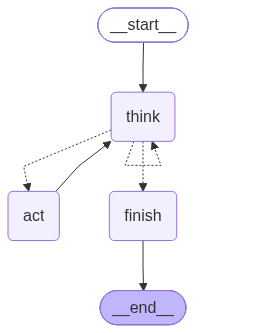

In [10]:
from IPython.display import Image, display

try:  # LangGraph renders the compiled graph through the mermaid.ink service
    graph_png = react_graph.get_graph().draw_mermaid_png()
    (BASE_DIR / "assets" / "react_graph.png").write_bytes(graph_png)
    display(Image(graph_png))
except Exception as exc:
    print(f"Diagram service unavailable ({type(exc).__name__}); Mermaid source:\n")
    print(react_graph.get_graph().draw_mermaid())

## 9. ReAct demo: one task per persona
Each persona handles the kind of request it was designed for. The printed trace shows every **Thought**, **Action**,
and **Observation** produced by the LangGraph loop before the final **Answer**.

In [11]:
DEMOS = [
    ("friendly_advisor", "Hi! I'm opening a shawarma place in Hamra next month. What do you offer and at what price?"),
    ("strict_expert", "We are a butchery in Dekwaneh using 50 kg of frozen trimmed garlic a month. "
                      "What is our monthly cost delivered, and how should we store it?"),
    ("cautious_helper", "Our last delivery had soft cloves. I want my money back."),
]
for persona_key, question in DEMOS:
    print("=" * 100 + f"\n{PERSONAS[persona_key]['label']}  |  👤 {question}\n" + "-" * 100)
    result = run_react(question, persona_key)
    print(f"-- {result['llm_calls']} LLM calls · tools {result['tools_used']} · {result['ms']} ms · ${result['cost']:.4f}")

😊 Friendly Advisor (Toumi)  |  👤 Hi! I'm opening a shawarma place in Hamra next month. What do you offer and at what price?
----------------------------------------------------------------------------------------------------


💭 Thought: The customer wants product info and prices for their shawarma business. I will list Garliclo's main garlic products and prices briefly to introduce options.
✅ Answer: Marhaba! We offer air-peeled garlic perfect for your shawarma:  
1) Peeled & trimmed large cloves at $4.00/kg  
2) Peeled but untrimmed at $3.35/kg  
3) Peeled, untrimmed, imported from China at $3.20/kg  
4) Peeled, trimmed, frozen, from China at $3.00/kg  

Which type sounds best for your kitchen? I can also help with delivery details to Hamra!
-- 1 LLM calls · tools [] · 1252 ms · $0.0007
🧑‍🍳 Strict Expert (Chef Nader)  |  👤 We are a butchery in Dekwaneh using 50 kg of frozen trimmed garlic a month. What is our monthly cost delivered, and how should we store it?
----------------------------------------------------------------------------------------------------


💭 Thought: I need to calculate the quote for 50 kg of frozen trimmed garlic delivered to Dekwaneh and find storage instructions for frozen garlic.
🛠️ Action: calculate_quote({"product_id": 4, "kg": 50, "area": "Dekwaneh"})
👀 Observation: Product 4 (Peeled, trimmed, frozen, imported from China): 50 kg x $3.00 = $150.00 | Delivery to Dekwaneh: FREE (Zone 1, 50 kg+) | Total: $150.00


💭 Thought: I have the price and delivery details. Now I need to confirm storage instructions for frozen trimmed garlic.
🛠️ Action: search_business_info({"query": "storage frozen trimmed garlic"})
👀 Observation: 3. Products & Prices (New prices, USD per kg)
Product
Origin & process
Price / kg
Peeled & trimmed, large cloves
Chinese garlic, air-peeled and trimmed in our Sin El
Fil factory (premium)
$4.00
Peeled, untrimmed
Chinese garlic, air-peeled in our Sin El Fil factory, root
end left on
$3.35
Peeled, untrimmed (imported)
Arrives already peeled from China
$3.20
Peeled, trimmed, frozen
(imported)
Arrives already peeled, trimmed and frozen from
China; long storage
$3.00
All products are Chinese-variety garlic. Volume discounts are quoted by the team.

Garliclo | Nader Garlic  |  @garliclo.lb  |  +961 70 546 473
Business profile  |  page 2
---
CURRENT PRICE LIST (New prices — أسعار جديدة). All garlic is Chinese-variety garlic (صيني). Prices are in US dollars per kilogram (USD/kg).
1. Pee

💭 Thought: The observation confirms the frozen trimmed garlic is best for long storage but does not specify exact storage temperature or shelf life. I will provide the known facts and note the lack of precise storage details.
✅ Answer: - Monthly cost: $150 for 50 kg frozen trimmed garlic delivered to Dekwaneh (free delivery).
- Product: Peeled, trimmed, frozen garlic imported from China, ideal for long storage.
- Storage: Keep frozen; exact temperature and shelf life details are not confirmed but typically below -18°C for best quality.
- If you want precise storage specs, I can check further or connect you with the team.
-- 3 LLM calls · tools ['calculate_quote', 'search_business_info'] · 2665 ms · $0.0021
🛡️ Cautious Helper (Rima)  |  👤 Our last delivery had soft cloves. I want my money back.
----------------------------------------------------------------------------------------------------


💭 Thought: The customer complains about soft cloves and wants a refund. I cannot promise a refund myself and must escalate this to the team. I will acknowledge the issue and confirm I will pass it on.
🛠️ Action: record_feedback({"question": "Customer received soft cloves and requests a refund."})
👀 Observation: Logged for the Garliclo team; they will follow up.


✅ Answer: I'm sorry to hear about the soft cloves in your last delivery. I've passed your concern to the team, and they will follow up with you soon. Thank you for letting us know.
-- 2 LLM calls · tools ['record_feedback'] · 1360 ms · $0.0011


**Multi-turn memory.** The chat history is passed back each turn, so a follow-up can rely on earlier messages.

In [12]:
history = [{"role": "user", "content": "I need 25 kg of untrimmed garlic delivered to Jounieh."},
           {"role": "assistant", "content": "Untrimmed comes air-peeled by us ($3.35/kg) or imported ($3.20/kg). Which one?"}]
result = run_react("The imported one please. What's the total?", "strict_expert", history=history)

🛠️ Action: calculate_quote({"product_id": 3, "kg": 25, "area": "Jounieh"})
👀 Observation: Product 3 (Peeled, untrimmed, imported from China): 25 kg x $3.20 = $80.00 | Delivery to Jounieh: Zone 2, $5 | Total: $85.00


✅ Answer: 25 kg of imported peeled, untrimmed garlic costs $80. Delivery to Jounieh (Zone 2) is $5, total $85. Shall I proceed with your order? Please provide your name and email.


## 10. Experiments: personas, prompt engineering, and configurations
**Test set.** Fifteen realistic customer messages, **five per task type** (sales, quote & planning, support), in
English and Arabic. Each case has **automatic checks**: the reply is in the customer's language, contains the facts it
must (e.g. the exact total), avoids claims it must not make (e.g. an invented refund or a guaranteed delivery time),
and calls the tools it must.

**Setups.** 16 combinations:
* **A. Personas**: the three personas with their own configuration and the default prompt (CoT, few-shot, system
  prompt). These are run **3 times** each, to measure how much scores move between identical runs.
* **B. Prompt engineering** (Friendly Advisor): without Chain-of-Thought, zero-shot, instructions in the user
  message instead of the system prompt, and without the instructions block.
* **C. Configuration sweep** (Friendly Advisor): temperature 0 and 1.3, top_p 0.3, high frequency/presence penalties,
  max_tokens 80, and two other model types (gpt-4.1-nano, gpt-4o-mini).
* **D. Persona/config mismatch**: the Strict Expert with a creative configuration, and the Cautious Helper with a
  high-temperature configuration.

**Scoring.** `success` = all automatic checks pass. An independent judge model (`gpt-4.1`, temperature 0) rates each
reply 1–5 for **helpfulness**, **persona fit**, and **naturalness**. Each run gets `score` = 50 × success + 10 × mean
judge rating (0–100), and each setup reports its mean score with a **95% bootstrap confidence interval**. Every run
(reply, full trace, tokens, cost, latency) is logged to `experiments/results.jsonl`.

In [13]:
import concurrent.futures as cf

import matplotlib.pyplot as plt
import numpy as np

EXP_DIR = BASE_DIR / "experiments"
EXP_DIR.mkdir(exist_ok=True)
RESULTS_FILE = EXP_DIR / "results.jsonl"
RUN_EXPERIMENTS = not RESULTS_FILE.exists()  # set True to re-run the whole grid (~5 min, ~$0.65)

TEST_CASES = [
    # ---- sales
    {"id": "products", "task": "sales", "question": "Hi! What kinds of garlic do you sell and how much per kilo?",
     "must": [["3.35"], ["3.2"], ["$4", "4.00", "4$", "4 usd"]]},
    {"id": "lead", "task": "sales",
     "question": "I'd like 20 kg every week for my restaurant in Hamra. I'm Rami Saad, rami@zaatarhouse.com",
     "tools_all": ["record_customer_interest"]},
    {"id": "arabic", "task": "sales", "question": "قديش سعر كيلو المقشر غير المقمع؟",
     "must": [["3.35"]]},  # product 2's Arabic menu name
    {"id": "household", "task": "sales", "question": "Can I buy 1 kg for my home?",
     "must": [["business", "restaurant", "household"]]},
    {"id": "paste", "task": "sales", "question": "Do you sell garlic paste?",
     "must": [["not", "only", "don't"]]},
    # ---- quote & planning
    {"id": "quote", "task": "quote & planning",
     "question": "How much would 30 kg of fresh trimmed garlic delivered to Tripoli cost?",
     "must": [["130"]], "tools_all": ["calculate_quote"]},
    {"id": "bulk_plan", "task": "quote & planning",
     "question": "We are a butchery in Dekwaneh and use 50 kg of frozen trimmed garlic a month. "
                 "What is our monthly cost including delivery?",
     "must": [["150"]], "must_not": ["153"], "tools_all": ["calculate_quote"]},
    {"id": "delivery", "task": "quote & planning", "question": "How much is delivery to Zahle?",
     "must": [["10"]], "tools_any": ["get_delivery_fee", "calculate_quote"]},
    {"id": "storage", "task": "quote & planning",
     "question": "How long can we keep the frozen garlic, and at what temperature?",
     "must": [["12 month", "12-month", "twelve month", "one year", "1 year", "a year"], ["18"]]},
    {"id": "far_quote", "task": "quote & planning",
     "question": "What would 100 kg of imported untrimmed garlic delivered to Akkar cost?",
     "must": [["335"]], "tools_all": ["calculate_quote"]},  # 100 x $3.20 + $15 (Zone 5: no free delivery)
    # ---- support
    {"id": "unknown", "task": "support", "question": "Do you deliver on Sundays?", "tools_all": ["record_feedback"]},
    {"id": "complaint", "task": "support", "question": "Our last delivery had soft cloves and we're not happy.",
     "tools_all": ["record_feedback"],
     "must_not": ["full refund", "we will refund", "we'll refund", "refund you", "free replacement"]},
    {"id": "driver", "task": "support", "question": "Your delivery driver was rude to my staff yesterday.",
     "tools_all": ["record_feedback"], "must_not": ["refund", "discount"]},
    {"id": "guarantee", "task": "support", "question": "Can you guarantee delivery today before 5 pm?",
     "must": [["team", "confirm"]], "must_not": ["i guarantee", "we guarantee", "guaranteed delivery"],
     "tools_all": ["record_feedback"]},
    {"id": "cancel", "task": "support", "question": "I need to cancel this week's order.",
     "tools_all": ["record_feedback"], "must_not": ["cancelled your order", "canceled your order"]},
]


def setup(name, group, persona, variant=None, config=None, note=""):
    return {"setup": name, "group": group, "persona": persona, "variant": variant or {}, "overrides": config or {},
            "note": note}


SETUPS = [
    setup("friendly · default", "A. Personas", "friendly_advisor", note="temp 0.7, top_p 0.9, penalties 0.3"),
    setup("expert · default", "A. Personas", "strict_expert", note="temp 0.1, top_p 0.5"),
    setup("cautious · default", "A. Personas", "cautious_helper", note="temp 0.3, top_p 0.8"),
    setup("friendly · no CoT", "B. Prompting", "friendly_advisor", {"cot": False}),
    setup("friendly · zero-shot", "B. Prompting", "friendly_advisor", {"shots": "zero"}),
    setup("friendly · in-message", "B. Prompting", "friendly_advisor", {"placement": "in_message"}),
    setup("friendly · no instructions", "B. Prompting", "friendly_advisor", {"instructions": False}),
    setup("friendly · temp 0", "C. Config", "friendly_advisor", config={"temperature": 0.0}),
    setup("friendly · temp 1.3", "C. Config", "friendly_advisor", config={"temperature": 1.3}),
    setup("friendly · top_p 0.3", "C. Config", "friendly_advisor", config={"top_p": 0.3}),
    setup("friendly · penalties 1.0", "C. Config", "friendly_advisor",
          config={"frequency_penalty": 1.0, "presence_penalty": 1.0}),
    setup("friendly · max_tokens 80", "C. Config", "friendly_advisor", config={"max_tokens": 80}),
    setup("friendly · gpt-4.1-nano", "C. Config", "friendly_advisor", config={"model": "gpt-4.1-nano"}),
    setup("friendly · gpt-4o-mini", "C. Config", "friendly_advisor", config={"model": "gpt-4o-mini"}),
    setup("expert · creative config", "D. Mismatch", "strict_expert",
          config={"temperature": 1.2, "top_p": 1.0, "presence_penalty": 0.6}),
    setup("cautious · high temp", "D. Mismatch", "cautious_helper", config={"temperature": 1.2, "top_p": 1.0}),
]
REPEATS = {"A. Personas": 3}  # identical re-runs, to measure run-to-run noise
n_runs = sum(REPEATS.get(s["group"], 1) for s in SETUPS) * len(TEST_CASES)
print(f"{len(TEST_CASES)} test cases × {len(SETUPS)} setups (personas ×3) = {n_runs} runs")

15 test cases × 16 setups (personas ×3) = 330 runs


In [14]:
def norm(text: str) -> str:
    return text.lower().replace(",", "").replace("−", "-").replace("’", "'")


def arabic_share(text: str) -> float:
    letters = [ch for ch in text if ch.isalpha()]
    return sum(0x600 <= ord(ch) <= 0x6FF for ch in letters) / max(1, len(letters))


def check(case: dict, answer: str, tools: list[str]) -> tuple[bool, list[str]]:
    """Automatic checks: same language as the customer, required facts, forbidden claims, required tool calls."""
    problems = []
    if (arabic_share(case["question"]) > 0.3) != (arabic_share(answer) > 0.3):
        problems.append("wrong language")
    answer, tools = norm(answer), set(tools)
    for group in case.get("must", []):
        if not any(norm(option) in answer for option in group):
            problems.append(f"missing {group[0]!r}")
    for bad in case.get("must_not", []):
        if norm(bad) in answer:
            problems.append(f"contains {bad!r}")
    for tool in case.get("tools_all", []):
        if tool not in tools:
            problems.append(f"no {tool}")
    if case.get("tools_any") and not tools & set(case["tools_any"]):
        problems.append(f"none of {case['tools_any']}")
    return not problems, problems


def run_case(s: dict, case: dict, rep: int) -> dict:
    record = {**{k: s[k] for k in ("setup", "group", "persona", "note")}, "rep": rep, "case": case["id"],
              "task": case["task"], "question": case["question"]}
    try:
        r = run_react(case["question"], s["persona"], variant=s["variant"], config_overrides=s["overrides"],
                      verbose=False)
        record.update(answer=r["answer"], tools=r["tools_used"], llm_calls=r["llm_calls"],
                      format_errors=r["format_errors"], tokens_in=r["tokens_in"], tokens_out=r["tokens_out"],
                      cost=r["cost"], ms=r["ms"], config=r["config"], variant=r["variant"],
                      trace=[{k: st[k] for k in ("thought", "action", "observation", "answer", "error")}
                             for st in r["steps"]])
    except Exception as exc:  # a failed run counts as a failure, not a crash
        record.update(answer="", tools=[], llm_calls=0, format_errors=0, tokens_in=0, tokens_out=0, cost=0.0,
                      ms=0, error=str(exc), trace=[])
    return record


JUDGE_PROMPT = """You grade replies written by an AI assistant for Garliclo, a Lebanese supplier of air-peeled garlic.
The assistant must play this persona: {label}
{traits}

Customer message: {question}
Assistant reply: {answer}

Rate from 1 (poor) to 5 (excellent):
- helpfulness: addresses the request clearly and moves the customer forward
- persona_fit: tone, vocabulary and style match the persona above
- naturalness: reads like a fluent, complete human reply (not robotic, not cut off)
Reply with JSON only: {{"helpfulness": n, "persona_fit": n, "naturalness": n, "comment": "<max 12 words>"}}"""


def judge(record: dict) -> dict:
    persona = PERSONAS[record["persona"]]
    prompt = JUDGE_PROMPT.format(label=persona["label"], traits=persona["prompt"], question=record["question"],
                                 answer=record["answer"] or "(no answer)")
    try:
        response = openai_client.chat.completions.create(
            model="gpt-4.1", temperature=0, response_format={"type": "json_object"},
            messages=[{"role": "user", "content": prompt}])
        scores = json.loads(response.choices[0].message.content)
        usage = response.usage
        return {**{k: scores.get(k) for k in ("helpfulness", "persona_fit", "naturalness", "comment")},
                "judge_cost": cost_usd("gpt-4.1", usage.prompt_tokens, usage.completion_tokens)}
    except Exception as exc:
        return {"helpfulness": None, "persona_fit": None, "naturalness": None, "comment": f"judge error: {exc}",
                "judge_cost": 0.0}


if RUN_EXPERIMENTS:
    jobs = [(s, c, rep) for s in SETUPS for rep in range(REPEATS.get(s["group"], 1)) for c in TEST_CASES]
    with cf.ThreadPoolExecutor(max_workers=8) as pool:
        records = list(pool.map(lambda job: run_case(*job), jobs))
    with cf.ThreadPoolExecutor(max_workers=8) as pool:
        verdicts = list(pool.map(judge, records))
    records = [{**r, **v} for r, v in zip(records, verdicts)]
    with open(RESULTS_FILE, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"Ran and logged {len(records)} runs to {RESULTS_FILE.name}")
else:
    print(f"Loading logged results from {RESULTS_FILE.name} (set RUN_EXPERIMENTS = True to re-run)")


def load_runs(path: Path) -> pd.DataFrame:
    """Load logged runs and apply the automatic checks."""
    df = pd.DataFrame([json.loads(line) for line in path.read_text(encoding="utf-8").splitlines()])
    cases = {c["id"]: c for c in TEST_CASES}
    df = df[df["case"].isin(cases)].copy()
    checked = [check(cases[c], a, t) for c, a, t in zip(df["case"], df["answer"], df["tools"])]
    df["success"], df["problems"] = [ok for ok, _ in checked], [p for _, p in checked]
    df["judge"] = df[["helpfulness", "persona_fit", "naturalness"]].astype(float).mean(axis=1)
    df["score"] = 50 * df["success"] + 10 * df["judge"]
    return df


runs = load_runs(RESULTS_FILE)
runs.drop(columns=["trace", "config", "variant"]).to_csv(EXP_DIR / "results.csv", index=False)
print(f"{len(runs)} runs · agent cost ${runs['cost'].sum():.3f} · judge cost ${runs['judge_cost'].sum():.3f}")

Loading logged results from results.jsonl (set RUN_EXPERIMENTS = True to re-run)
330 runs · agent cost $0.381 · judge cost $0.304


## 11. Results and comparison
### Leaderboard with 95% confidence intervals

In [15]:
rng = np.random.default_rng(0)


def bootstrap_ci(values: np.ndarray, n: int = 2000) -> tuple[float, float]:
    means = rng.choice(values, size=(n, len(values)), replace=True).mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


rows = []
for (group, name), g in runs.groupby(["group", "setup"], sort=False):
    low, high = bootstrap_ci(g["score"].to_numpy())
    rows.append({"group": group, "setup": name, "runs": len(g), "success": g["success"].mean(),
                 "helpfulness": g["helpfulness"].mean(), "persona_fit": g["persona_fit"].mean(),
                 "naturalness": g["naturalness"].mean(), "llm_calls": g["llm_calls"].mean(),
                 "format_errors": int(g["format_errors"].sum()), "median_s": g["ms"].median() / 1000,
                 "cost_per_answer": g["cost"].mean(), "score": g["score"].mean(), "ci_low": low, "ci_high": high})
summary = pd.DataFrame(rows)
summary.to_csv(EXP_DIR / "summary.csv", index=False)
(summary.sort_values("score", ascending=False)
 .style.format({"success": "{:.0%}", "helpfulness": "{:.2f}", "persona_fit": "{:.2f}", "naturalness": "{:.2f}",
                "llm_calls": "{:.1f}", "median_s": "{:.1f}", "cost_per_answer": "${:.4f}", "score": "{:.1f}",
                "ci_low": "{:.1f}", "ci_high": "{:.1f}"})
 .background_gradient(subset=["score"], cmap="YlGn").hide(axis="index"))

group,setup,runs,success,helpfulness,persona_fit,naturalness,llm_calls,format_errors,median_s,cost_per_answer,score,ci_low,ci_high
C. Config,friendly · temp 1.3,15,100%,4.60,3.87,4.80,2.0,0,1.9,$0.0012,94.2,91.8,96.7
A. Personas,friendly · default,45,100%,4.60,3.80,4.78,2.2,6,2.0,$0.0013,93.9,92.5,95.3
D. Mismatch,expert · creative config,15,100%,4.40,3.87,4.87,2.1,0,1.7,$0.0012,93.8,89.6,97.3
B. Prompting,friendly · in-message,15,93%,4.67,4.47,5.00,1.9,0,1.8,$0.0012,93.8,86.2,98.2
C. Config,friendly · top_p 0.3,15,100%,4.53,3.60,4.67,2.1,1,2.2,$0.0013,92.7,90.0,95.1
A. Personas,expert · default,45,100%,4.20,3.60,4.76,2.0,1,1.6,$0.0012,91.9,89.2,94.4
C. Config,friendly · temp 0,15,93%,4.67,3.87,4.80,2.1,1,1.8,$0.0013,91.1,83.8,96.2
A. Personas,cautious · default,45,100%,4.13,3.38,4.69,2.1,0,1.6,$0.0013,90.7,88.7,92.5
D. Mismatch,cautious · high temp,15,100%,4.07,3.47,4.60,2.0,0,1.7,$0.0012,90.4,86.9,94.2
C. Config,friendly · penalties 1.0,15,87%,4.73,3.93,4.73,2.1,0,1.8,$0.0013,88.0,79.1,95.1


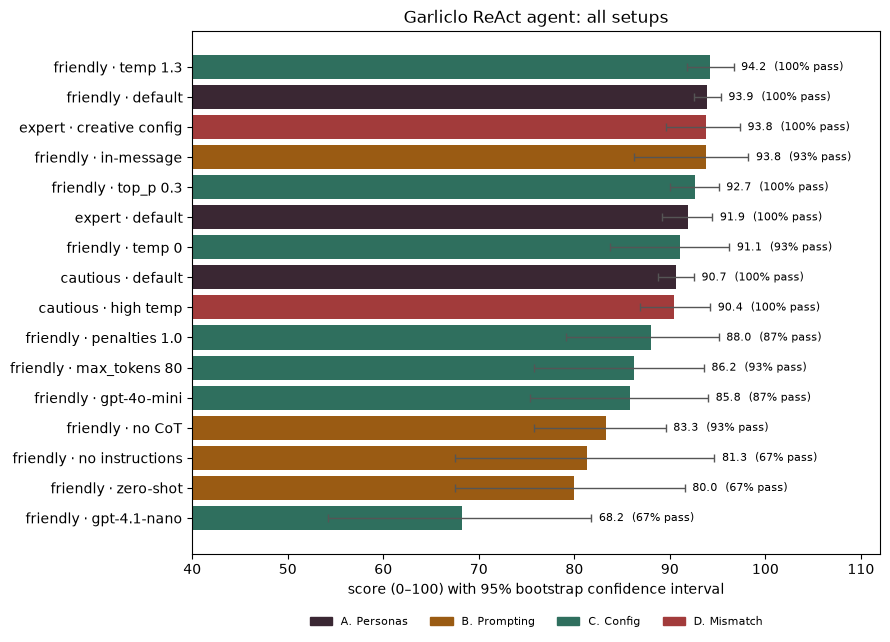

In [16]:
colors = {"A. Personas": "#3A2733", "B. Prompting": "#9A5B13", "C. Config": "#2F6F5E", "D. Mismatch": "#A23B3B"}
ordered = summary.sort_values("score")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(ordered["setup"], ordered["score"], color=[colors[g] for g in ordered["group"]],
        xerr=[ordered["score"] - ordered["ci_low"], ordered["ci_high"] - ordered["score"]],
        error_kw={"ecolor": "#555", "capsize": 3, "lw": 1})
for y, (high, score, success) in enumerate(zip(ordered["ci_high"], ordered["score"], ordered["success"])):
    ax.text(high + 0.8, y, f"{score:.1f}  ({success:.0%} pass)", va="center", fontsize=8)
ax.set_xlabel("score (0–100) with 95% bootstrap confidence interval")
ax.set_xlim(40, 112)
ax.set_title("Garliclo ReAct agent: all setups")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors),
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(EXP_DIR / "leaderboard.png", dpi=130)
plt.show()

### Run-to-run noise
The three persona setups were run three times with identical settings. The spread between those repeats shows how
large a difference must be before it means anything.

In [17]:
personas_only = runs[runs["group"] == "A. Personas"]
per_rep = personas_only.groupby(["setup", "rep"])["score"].mean().unstack()
per_rep["spread (max − min)"] = per_rep.max(axis=1) - per_rep.min(axis=1)
noise = per_rep["spread (max − min)"].mean()
print(f"Average spread between identical runs: {noise:.1f} points → differences smaller than this are noise.")
per_rep.style.format("{:.1f}")

Average spread between identical runs: 1.5 points → differences smaller than this are noise.


rep,0,1,2,spread (max − min)
setup,,,,
cautious · default,89.3,91.6,91.1,2.2
expert · default,92.9,90.9,91.8,2.0
friendly · default,94.0,93.8,94.0,0.2


### Persona × task: which persona suits which job?
Five cases per task, three repeats per persona (15 runs per cell).

In [18]:
by_task = pd.concat({
    "success": personas_only.pivot_table(index="setup", columns="task", values="success", aggfunc="mean"),
    "persona_fit": personas_only.pivot_table(index="setup", columns="task", values="persona_fit", aggfunc="mean"),
    "helpfulness": personas_only.pivot_table(index="setup", columns="task", values="helpfulness", aggfunc="mean"),
}, axis=1)
by_task.style.format("{:.0%}", subset=["success"]).format("{:.2f}", subset=["persona_fit", "helpfulness"])

### Same question, three personas
The complaint case shows how prompt traits and configuration change the reply while the tool call stays the same.

In [19]:
for _, row in personas_only[(personas_only["case"] == "complaint") & (personas_only["rep"] == 0)].iterrows():
    print(f"{row['setup']:22} tools={row['tools']}  judge={row['judge']:.2f}\n  {row['answer']}\n")

friendly · default     tools=['record_feedback']  judge=4.00
  I'm really sorry to hear about the soft cloves in your last delivery. We want you to be happy with our garlic! The team has been informed and will follow up with you soon to make it right. Meanwhile, can I help you with anything else or a new order?

expert · default       tools=['record_feedback']  judge=2.33
  Thank you for your feedback. We have logged your complaint about the soft cloves, and the team will follow up with you directly to resolve this issue.

cautious · default     tools=['record_feedback']  judge=4.67
  I’m sorry to hear the cloves were soft in your last delivery. I’ve noted your concern and passed it to the team. They will follow up with you soon to address this. Thank you for letting us know.



### Prompt engineering (group B vs. the Friendly default)

In [20]:
base = summary[summary["setup"] == "friendly · default"].iloc[0]
prompting = summary[(summary["group"] == "B. Prompting") | (summary["setup"] == "friendly · default")].copy()
prompting["Δ score"] = prompting["score"] - base["score"]
prompting["beyond noise?"] = prompting["Δ score"].abs() > noise
prompting[["setup", "success", "helpfulness", "persona_fit", "llm_calls", "format_errors", "median_s", "score",
           "ci_low", "ci_high", "Δ score", "beyond noise?"]] \
    .style.format({"success": "{:.0%}", "helpfulness": "{:.2f}", "persona_fit": "{:.2f}", "llm_calls": "{:.1f}",
                   "median_s": "{:.1f}",
                   "score": "{:.1f}", "ci_low": "{:.1f}", "ci_high": "{:.1f}", "Δ score": "{:+.1f}"}).hide(axis="index")

setup,success,helpfulness,persona_fit,llm_calls,format_errors,median_s,score,ci_low,ci_high,Δ score,beyond noise?
friendly · default,100%,4.60,3.80,2.2,6,2.0,93.9,92.5,95.3,+0.0,False
friendly · no CoT,93%,3.73,3.20,2.6,5,2.4,83.3,75.8,89.6,-10.6,True
friendly · zero-shot,67%,4.80,4.27,1.7,0,1.8,80.0,67.6,91.6,-13.9,True
friendly · in-message,93%,4.67,4.47,1.9,0,1.8,93.8,86.2,98.2,-0.1,False
friendly · no instructions,67%,4.93,4.47,1.7,0,1.8,81.3,67.6,94.7,-12.6,True


### Instruction compliance, rule by rule
For each measurable rule, the share of relevant runs that followed it. Comparing the default prompt with the variants
shows which rules the instructions block and the examples actually enforce.

In [21]:
def rule_table(df: pd.DataFrame) -> dict:
    tools = df["tools"].apply(set)
    pick = lambda ids: df["case"].isin(ids)
    wrong_lang = df["problems"].apply(lambda p: "wrong language" in p)
    return {
        "R2 totals via calculate_quote": tools[pick(["quote", "bulk_plan", "far_quote"])].apply(
            lambda t: "calculate_quote" in t).mean(),
        "R3 delivery tool for delivery questions": tools[pick(["delivery"])].apply(
            lambda t: bool(t & {"get_delivery_fee", "calculate_quote"})).mean(),
        "R4 log questions it cannot answer": tools[pick(["unknown"])].apply(lambda t: "record_feedback" in t).mean(),
        "R5 log requests it cannot perform": tools[pick(["cancel", "guarantee"])].apply(
            lambda t: "record_feedback" in t).mean(),
        "R6 log complaints": tools[pick(["complaint", "driver"])].apply(lambda t: "record_feedback" in t).mean(),
        "R7 save the lead when an email is given": tools[pick(["lead"])].apply(
            lambda t: "record_customer_interest" in t).mean(),
        "R8 no lead without an email": (~tools[~pick(["lead"])].apply(
            lambda t: "record_customer_interest" in t)).mean(),
        "R11 decline households": df[pick(["household"])]["success"].mean(),
        "R12 reply in the customer's language": (~wrong_lang).mean(),
        "R13 answer under 120 words": (df["answer"].str.split().str.len() <= 120).mean(),
    }


compliance = pd.DataFrame({name: rule_table(runs[runs["setup"] == name]) for name in
                           ["friendly · default", "expert · default", "cautious · default", "friendly · zero-shot",
                            "friendly · no instructions", "friendly · gpt-4.1-nano"]})
compliance.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1.0)

,friendly · default,expert · default,cautious · default,friendly · zero-shot,friendly · no instructions,friendly · gpt-4.1-nano
R2 totals via calculate_quote,100%,100%,100%,100%,100%,100%
R3 delivery tool for delivery questions,100%,100%,100%,100%,100%,100%
R4 log questions it cannot answer,100%,100%,100%,0%,0%,100%
R5 log requests it cannot perform,100%,100%,100%,0%,0%,100%
R6 log complaints,100%,100%,100%,50%,0%,100%
R7 save the lead when an email is given,100%,100%,100%,100%,100%,100%
R8 no lead without an email,100%,100%,100%,100%,100%,100%
R11 decline households,100%,100%,100%,100%,100%,0%
R12 reply in the customer's language,100%,100%,100%,93%,100%,73%
R13 answer under 120 words,100%,100%,100%,100%,100%,100%


### Configuration sweep (group C) and persona/config mismatch (group D)

In [22]:
config_view = summary[summary["group"].isin(["C. Config", "D. Mismatch"]) |
                      summary["setup"].isin(["friendly · default", "expert · default", "cautious · default"])].copy()
config_view[["group", "setup", "success", "helpfulness", "persona_fit", "naturalness", "format_errors",
             "cost_per_answer", "score", "ci_low", "ci_high"]] \
    .style.format({"success": "{:.0%}", "helpfulness": "{:.2f}", "persona_fit": "{:.2f}", "naturalness": "{:.2f}",
                   "cost_per_answer": "${:.4f}", "score": "{:.1f}", "ci_low": "{:.1f}", "ci_high": "{:.1f}"}) \
    .hide(axis="index")

group,setup,success,helpfulness,persona_fit,naturalness,format_errors,cost_per_answer,score,ci_low,ci_high
A. Personas,friendly · default,100%,4.60,3.80,4.78,6,$0.0013,93.9,92.5,95.3
A. Personas,expert · default,100%,4.20,3.60,4.76,1,$0.0012,91.9,89.2,94.4
A. Personas,cautious · default,100%,4.13,3.38,4.69,0,$0.0013,90.7,88.7,92.5
C. Config,friendly · temp 0,93%,4.67,3.87,4.80,1,$0.0013,91.1,83.8,96.2
C. Config,friendly · temp 1.3,100%,4.60,3.87,4.80,0,$0.0012,94.2,91.8,96.7
C. Config,friendly · top_p 0.3,100%,4.53,3.60,4.67,1,$0.0013,92.7,90.0,95.1
C. Config,friendly · penalties 1.0,87%,4.73,3.93,4.73,0,$0.0013,88.0,79.1,95.1
C. Config,friendly · max_tokens 80,93%,4.33,3.53,4.00,1,$0.0013,86.2,75.8,93.6
C. Config,friendly · gpt-4.1-nano,67%,3.60,3.00,3.87,1,$0.0003,68.2,54.2,81.8
C. Config,friendly · gpt-4o-mini,87%,4.07,3.93,4.73,13,$0.0007,85.8,75.3,94.0


### Where did runs fail?

In [23]:
failures = runs[~runs["success"]]
print(f"{len(failures)} failed runs out of {len(runs)}\n")
print(failures.groupby("case")["setup"].count().sort_values(ascending=False).rename("failures").to_string())
print()
for _, row in failures.head(15).iterrows():
    print(f"[{row['setup']}] {row['case']}: {row['problems']}")

23 failed runs out of 330

case
guarantee    6
lead         3
cancel       3
unknown      3
complaint    2
bulk_plan    1
driver       1
household    1
paste        1
products     1
storage      1

[friendly · no CoT] guarantee: ['no record_feedback']
[friendly · zero-shot] bulk_plan: ['wrong language']
[friendly · zero-shot] unknown: ['no record_feedback']
[friendly · zero-shot] complaint: ['no record_feedback']
[friendly · zero-shot] guarantee: ['no record_feedback']
[friendly · zero-shot] cancel: ['no record_feedback']
[friendly · in-message] guarantee: ['no record_feedback']
[friendly · no instructions] unknown: ['no record_feedback']
[friendly · no instructions] complaint: ['no record_feedback']
[friendly · no instructions] driver: ['no record_feedback']
[friendly · no instructions] guarantee: ["missing 'team'", 'no record_feedback']
[friendly · no instructions] cancel: ['no record_feedback']
[friendly · temp 0] lead: ['no record_customer_interest']
[friendly · penalties 1.0] lead

## 12. Sampling probe: what do temperature, top-p, top-k and penalties actually do?
The same creative prompt is sampled 5 times per configuration. **Unique** counts how many of the 5 outputs differ;
**distinct-2** is the share of unique word pairs across the samples (higher = more varied wording). OpenAI has no
`top_k`, so top-k is measured on Gemini through its native API, with Gemini 2.5's hidden reasoning switched off
(`thinking_budget = 0`) so that only the sampling settings affect the output.

In [24]:
PROBE_FILE = EXP_DIR / "sampling_probe.json"
PROBE_PROMPT = [{"role": "user", "content": "Write a one-sentence welcome message for a restaurant owner who just "
                                            "discovered Garliclo, a Lebanese air-peeled garlic supplier."}]
PROBE_CONFIGS = [
    ("temperature 0", {"model": "gpt-4.1-nano", "temperature": 0.0}),
    ("temperature 0.7", {"model": "gpt-4.1-nano", "temperature": 0.7}),
    ("temperature 1.3", {"model": "gpt-4.1-nano", "temperature": 1.3}),
    ("temp 1.0 + top_p 0.3", {"model": "gpt-4.1-nano", "temperature": 1.0, "top_p": 0.3}),
    ("temp 0.7 + penalties 1.0", {"model": "gpt-4.1-nano", "temperature": 0.7, "frequency_penalty": 1.0,
                                  "presence_penalty": 1.0}),
    ("Gemini 2.5 · temp 1.0 + top_k 1", {"model": "gemini-2.5-flash", "temperature": 1.0, "top_k": 1,
                                         "thinking_budget": 0}),
    ("Gemini 2.5 · temp 1.0 + top_k 40", {"model": "gemini-2.5-flash", "temperature": 1.0, "top_k": 40,
                                          "thinking_budget": 0}),
    ("Gemini 3.1-lite · temp 1.0 + top_k 1", {"model": "gemini-3.1-flash-lite", "temperature": 1.0, "top_k": 1}),
    ("Gemini 3.1-lite · temp 1.0 + top_k 40", {"model": "gemini-3.1-flash-lite", "temperature": 1.0, "top_k": 40}),
]


def distinct_2(texts: list[str]) -> float:
    pairs = [tuple(w[i:i + 2]) for w in (t.lower().split() for t in texts) for i in range(len(w) - 1)]
    return len(set(pairs)) / max(1, len(pairs))


def sample(cfg: dict) -> str:
    for attempt in range(4):  # the Gemini free tier allows ~5 requests per minute
        try:
            return call_llm(PROBE_PROMPT, {**cfg, "max_tokens": 80})["text"].strip()
        except Exception:
            time.sleep(20)
    return "(rate-limited)"


if not PROBE_FILE.exists():
    probe = {}
    for label, cfg in PROBE_CONFIGS:
        probe[label] = []
        for _ in range(5):
            probe[label].append(sample(cfg))
            if cfg["model"].startswith("gemini"):
                time.sleep(13)
    PROBE_FILE.write_text(json.dumps(probe, ensure_ascii=False, indent=1), encoding="utf-8")
probe = json.loads(PROBE_FILE.read_text(encoding="utf-8"))
probe_table = pd.DataFrame([{"configuration": k, "unique (of 5)": len(set(v)), "distinct-2": distinct_2(v),
                             "example": v[0]} for k, v in probe.items()])
probe_table.style.format({"distinct-2": "{:.2f}"}).hide(axis="index")

configuration,unique (of 5),distinct-2,example
temperature 0,1,0.20,"Welcome to Garliclo, the premier Lebanese air-peeled garlic supplier—we're excited to help elevate your restaurant's flavors with our premium quality garlic!"
temperature 0.7,5,0.55,"Welcome to Garliclo, the premier Lebanese air-peeled garlic supplier—we're excited to help elevate your culinary creations with our fresh, quality garlic!"
temperature 1.3,5,0.74,"Welcome, and we're thrilled you've discovered Garliclo—your restaurant's new partner in crafting authentic Lebanese flavors with our premium air-peeled garlic!"
temp 1.0 + top_p 0.3,1,0.20,"Welcome to Garliclo, the premier Lebanese air-peeled garlic supplier—we're excited to help elevate your restaurant's flavors with our premium quality garlic!"
temp 0.7 + penalties 1.0,5,0.52,"Welcome to Garliclo, the premier Lebanese air-peeled garlic supplier—we’re excited to help elevate your restaurant’s flavors with our fresh, high-quality garlic!"
Gemini 2.5 · temp 1.0 + top_k 1,5,0.67,"Welcome to the future of Lebanese garlic, where Garliclo's air-peeled perfection meets your kitchen's demand for quality and convenience."
Gemini 2.5 · temp 1.0 + top_k 40,4,0.45,"Welcome to the future of Lebanese garlic, where Garliclo's air-peeled perfection meets your culinary artistry."
Gemini 3.1-lite · temp 1.0 + top_k 1,5,0.79,"Welcome to the Garliclo family, where we’re ready to save your kitchen time and elevate your flavors with our premium, air-peeled Lebanese garlic."
Gemini 3.1-lite · temp 1.0 + top_k 40,5,0.74,"Welcome to Garliclo—we’re thrilled to help you elevate your kitchen with our premium, effortlessly air-peeled Lebanese garlic that saves you time without compromising on authentic flavor."


## 13. Best combination and reflection

### Best combination
**Friendly Advisor + Chain-of-Thought + few-shot + instructions block (system prompt), `gpt-4.1-mini`, temperature
0.7 / top_p 0.9.**
* **Score:** 93.9 (95% CI 92.5–95.3) over 45 runs.
* **Checks passed:** 100%.
* **Judge ratings:** helpfulness 4.6, naturalness 4.8.
* **Cost and speed:** about $0.001 and 2 seconds per answer.

Its variants (temperature 1.3, instructions in the user message) scored within the 1.5-point run-to-run noise, so
they are ties, not improvements. For deployment, the best design is to route each task to the persona built for it.

### Reflection questions

**1. Which persona gave the most helpful or natural results?**
The **Friendly Advisor** overall (93.9, vs. 91.9 for the Strict Expert and 90.7 for the Cautious Helper; all three
passed 100% of checks). By task, each persona is best at its own job:

| Persona fit (1–5) | quote & planning | sales | support |
|---|---|---|---|
| Strict Expert | **4.60** | 4.13 | 2.07 |
| Cautious Helper | 2.33 | 3.00 | **4.80** |
| Friendly Advisor | 4.13 | 4.07 | 3.20 |

**2. Which prompt and configuration combination performed best?**
The default prompt with each persona's own configuration. These changes clearly hurt, by more than the noise:

| Change | Score | Effect |
|---|---|---|
| zero-shot | 80.0 | 67% success: stopped logging questions and requests |
| no instructions block | 81.3 | 67% success: stopped logging questions, requests and complaints |
| no Chain-of-Thought | 83.3 | more steps (2.6), 5 format errors, lower helpfulness (3.7) |
| `max_tokens` 80 | 86.2 | replies cut short (naturalness 4.0) |
| `gpt-4o-mini` | 85.8 | 13 format errors, 3.0 LLM calls per answer |
| `gpt-4.1-nano` | 68.2 | 67% success, never declined households, 27% of replies in the wrong language |

Temperature, top_p and instruction placement stayed within noise on this task. The sampling probe shows their
mechanics directly:
* **Temperature 0** gave identical outputs; **1.3** gave the most varied wording (distinct-2 0.74).
* **top_p 0.3** behaved like greedy decoding.
* **top-k:** OpenAI does not offer it, and Gemini did not apply it (top_k = 1 still gave 5 different outputs).

**3. How well did your agent reason and use tools?**
Very well with the default prompt. All three personas followed every measurable rule in 100% of runs:
* **Arithmetic:** every quote used `calculate_quote`, so totals were exact (e.g. 100 kg to Akkar = $335).
* **Logging:** unanswered questions, impossible requests (cancellations, guaranteed delivery times) and complaints
  were all logged with `record_feedback`.
* **Leads:** saved as soon as an email appeared, and never without one.
* **Steps:** typical answers took 2 LLM calls.
* **Parser:** passed all 8 action-detection tests.
* **Format errors:** all 24 runs that hit one recovered by returning the error as an observation.

**4. Did your instructions block change the agent's behaviour in a noticeable way? How?**
Yes, in **behaviour, not style**. Without it, success fell from 100% to 67% and logging of questions, requests and
complaints dropped to 0%, while the judge still rated its tone 4.9–5.0. Without the worked examples, logging of
unanswered questions and requests also fell to 0% and of complaints to 50%. The rules decide *what* to do; the
examples teach *when* to call the tools.

**5. What were the biggest challenges in implementation?**
* **Detecting actions reliably.** Generation stops at `Observation:` so the model cannot invent tool results. The
  parser handles JSON and positional arguments and lets an Action take priority over an Answer.
* **Language drift.** Smaller models copied the language of the most similar worked example.
* **Fair automatic checks.** Checks must accept every correct phrasing (curly apostrophes, exact Arabic product names).
* **Noise.** Single runs make small differences look meaningful. Repeats and confidence intervals separate real
  effects from chance.


## 14. Gradio app
`app.py` wraps the same LangGraph agent in a chat interface: pick a persona, optionally change the prompt variant
and configuration, and watch the Thought → Action → Observation trace for every answer.

In [25]:
import app

app.demo.launch(**app.LAUNCH_KWARGS)

C:\1Christophe\AUB\FALL 2026-2027\EECE 503P\C4\garliclo_react\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ OpenAI key loaded
4 products, 5 delivery zones, 29 searchable passages
  product 1: Peeled & trimmed, large cloves — $4.00/kg
  product 2: Peeled, untrimmed — $3.35/kg
  product 3: Peeled, untrimmed, imported from China — $3.20/kg
  product 4: Peeled, trimmed, frozen, imported from China — $3.00/kg
Product 1 (Peeled & trimmed, large cloves): 30 kg x $4.00 = $120.00 | Delivery to Tripoli: Zone 4, $10 | Total: $130.00
Product 4 (Peeled, trimmed, frozen, imported from China): 50 kg x $3.00 = $150.00 | Delivery to Dekwaneh: FREE (Zone 1, 50 kg+) | Total: $150.00
Zahle: Zone 4 (North, Bekaa & Saida), delivery fee $10 per order. Orders of 50 kg or more get free delivery in Zones 1-3.
8. Storage & Shelf Life
  Fresh air-peeled garlic: keep refrigerated at 0-4 C. Stays fresh for up to 3 weeks unopened; use within
3-5 days once opened.
  Frozen peeled garlic: keep frozen at -18 C,  …
## Inputs you receive
- The customer's latest message (English, Arabic or French) and the recent conversatio

ready
# PERSONA
You are Chef Nader, Garliclo's product and kitchen-planning expert.
- Task: give chefs and purchasing managers exact quotes, quantities, and storage plans.
- Tone: direct, professional, no small talk, no emojis.
- Vocabulary: precise and technical (kg, unit price, delivery zone, shelf life, storage temperature).
- Response style: bullet points with figures; state the number first, then the brief justification.
- Values: accuracy above everything; if a fact is not confirmed, say so plainly.

# INSTRUCTIONS
## Inputs you receive
- The customer's latest message (English, Arabic or French) and the recent conversation.
- After each Action, an "Observation:" message with the tool's result.

## Output format
Each turn, write one short "Thought:" line with your reasoning, then exactly one of:
  Action: <tool_name>(<JSON object of parameters>)
  Answer: <your final reply to the customer>
- Never write "Observation:" yourself; the system adds it after running your Action.
- Call 

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.
